# Comparación de modelos: árbol de decisión vs. Naive Bayes vs. KNN
**Proyecto:** Análisis del catálogo de Netflix y la valoración de usuarios · UNIMINUTO Ibagué

**Pregunta:** ¿Cuál de los tres modelos conviene usar para predecir si un título tendrá valoración alta (≥ 85)?

**Cómo se compara de forma justa:** mismos 137 títulos y mismas 22 variables; misma partición 70/30 (`random_state=42`); mismos pliegues de validación cruzada repetida (5 × 10 = 50 evaluaciones). El KNN escala las variables dentro de un `Pipeline` (así el escalador solo ve los datos de entrenamiento de cada pliegue) y elige su `k` con una validación interna, de modo que la estimación sigue siendo honesta.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option('display.width', 200)
from src.lectorDatos import LectorDatos
from src.limpiadorDatos import LimpiadorDatos
from src.modeloArbol import ModeloArbol
from src.modeloNaiveBayes import ModeloNaiveBayes
from src.modeloKNN import ModeloKNN
from src.comparadorModelos import ComparadorModelos

catalogo = LectorDatos('../CSV/netflix_titles.csv').cargarDatos()
limp = LimpiadorDatos(catalogo); limp.limpiarDatos(); catalogo = limp.corregirYProcesar()
valoraciones = LimpiadorDatos(LectorDatos('../CSV/netflix.csv').cargarDatos()).limpiarDatos()

arbol = ModeloArbol(maxProfundidad=4, umbral=85)
X, y = arbol.prepararDatos(valoraciones, catalogo)
print('Títulos:', len(X), '| Variables:', X.shape[1], '| Línea base (clase más común):', round(max(y.mean(), 1 - y.mean()), 3))

Duplicados eliminados: 0
Duplicados eliminados: 500
Títulos: 137 | Variables: 22 | Línea base (clase más común): 0.54


## 1. Los tres modelos
- **Árbol de decisión** (profundidad máx. 4): reglas de sí/no. No necesita escalar.
- **Naive Bayes gaussiano:** combina la probabilidad de cada variable por clase, suponiendo que son independientes. No necesita escalar.
- **KNN:** clasifica según los *k* títulos más parecidos. Mide distancias, por eso **sí** necesita escalar (`StandardScaler`).

In [2]:
comp = ComparadorModelos(X, y)
comp.agregar('Árbol de decisión', arbol.estimador())
comp.agregar('Naive Bayes', ModeloNaiveBayes().estimador())
comp.agregar('KNN', ModeloKNN('standard').estimador())
tabla = comp.comparar()
display(tabla.round(3))

,exactitud_cv,desviacion,f1_alta,auc,exactitud_entrenamiento,sobreajuste,exactitud_prueba_70_30
modelo,,,,,,,
Árbol de decisión,0.589,0.087,0.578,0.600,0.773,0.184,0.595
Naive Bayes,0.623,0.082,0.537,0.698,0.670,0.047,0.524
KNN,0.610,0.080,0.612,0.640,0.739,0.128,0.500


**Cómo leer la tabla.** `exactitud_cv` es el acierto promedio en 50 evaluaciones; `f1_alta` mide qué tan bien encuentra los títulos de valoración alta; `auc` mide qué tan bien ordena los títulos de menor a mayor probabilidad de ser altos (0,5 = azar); `sobreajuste` = exactitud en entrenamiento − exactitud en validación (más alto = el modelo memoriza). `exactitud_prueba_70_30` viene de un solo conjunto de prueba de 42 títulos, por eso es mucho menos confiable que la validación cruzada.

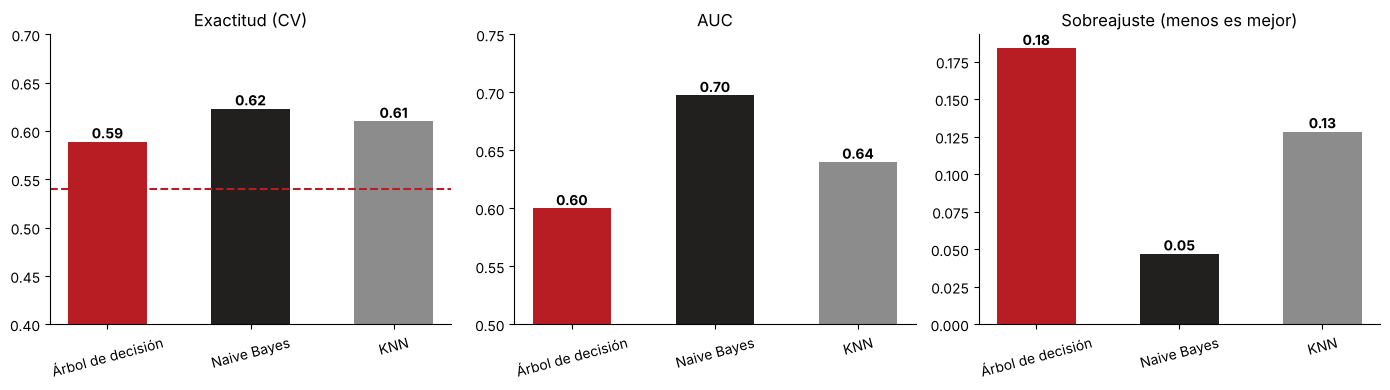

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
col = ['#B81D24', '#221F1F', '#8C8C8C']
for ax, (c, titulo) in zip(axs, [('exactitud_cv', 'Exactitud (CV)'), ('auc', 'AUC'), ('sobreajuste', 'Sobreajuste (menos es mejor)')]):
    ax.bar(tabla.index, tabla[c], color=col, width=.55); ax.set_title(titulo)
    for i, v in enumerate(tabla[c]): ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontweight='bold')
    ax.tick_params(axis='x', rotation=15); ax.spines[['top', 'right']].set_visible(False)
axs[0].axhline(comp.lineaBase, color='#B81D24', ls='--'); axs[0].set_ylim(0.4, 0.7); axs[1].set_ylim(0.5, 0.75)
plt.tight_layout(); plt.show()

## 2. ¿Las diferencias son reales o ruido?

In [4]:
display(comp.pruebaPareada('Árbol de decisión').round(3))
print('Desviación de la exactitud entre pliegues:', tabla.desviacion.round(3).to_dict())

,diferencia_media,p_valor,pliegues_que_gana
modelo,,,
Naive Bayes,0.034,0.548,0.56
KNN,0.021,0.733,0.44


Desviación de la exactitud entre pliegues: {'Árbol de decisión': 0.087, 'Naive Bayes': 0.082, 'KNN': 0.08}


La prueba compara cada modelo con el árbol **en los mismos pliegues**, con la corrección de Nadeau-Bengio (los pliegues repetidos no son independientes). Un `p_valor` mayor a 0,05 significa que la diferencia podría ser casualidad.

## 3. Escalamiento en KNN: aquí sí importa

,exactitud,desviacion
Sin escalar,0.577,0.091
StandardScaler,0.629,0.076
MinMaxScaler,0.601,0.065


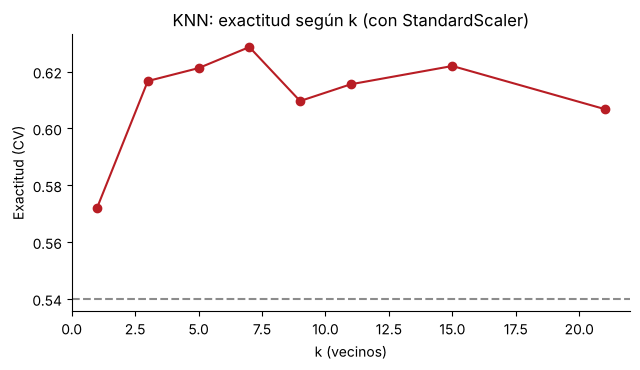

In [5]:
k = 7
efecto = ModeloKNN().efectoEscalamiento(X, y, comp.cv, k)
display(efecto.round(3))
curva = ModeloKNN().curvaK(X, y, comp.cv)
fig, ax = plt.subplots(figsize=(6.5, 3.8)); ax.plot(curva.index, curva.values, marker='o', color='#B81D24')
ax.axhline(comp.lineaBase, color='#8C8C8C', ls='--'); ax.set_xlabel('k (vecinos)'); ax.set_ylabel('Exactitud (CV)'); ax.set_title('KNN: exactitud según k (con StandardScaler)')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

Sin escalar, el año de lanzamiento (≈ 2.000) y los minutos dominan la distancia y el KNN pierde unos 5 puntos. Con `StandardScaler` rinde mejor que con `MinMaxScaler`. Esta es la diferencia con el árbol y Naive Bayes, donde escalar no cambia nada.

## 4. Conclusión: ¿cuál conviene usar?

**Lo primero: ninguno es claramente mejor.** Los tres superan la línea base (54,0 % de adivinar la clase más común) por 5 a 8 puntos, pero las diferencias entre modelos caen dentro del ruido: Naive Bayes vs. árbol, +3,4 puntos (p = 0,55); KNN vs. árbol, +2,1 puntos (p = 0,73); y la desviación entre pliegues es de unos 8 puntos. Con 137 títulos no se puede afirmar que uno sea mejor por exactitud.

**Lo que sí los distingue:**

| | Árbol de decisión | Naive Bayes | KNN |
|---|---|---|---|
| Exactitud (validación cruzada) | 58,9 % | **62,3 %** | 61,0 % |
| AUC (qué tan bien ordena) | 0,60 | **0,70** | 0,64 |
| F1 de valoración alta | 0,58 | 0,54 | **0,61** |
| Sobreajuste (entrenamiento − validación) | 18,4 pts | **4,7 pts** | 12,8 pts |
| ¿Explica por qué? | **Sí, con reglas** | Parcial | No |
| ¿Necesita escalar? | No | No | **Sí** (sin escalar pierde ≈ 5 pts) |

La exactitud del conjunto de prueba 70/30 (árbol 59,5 %, Naive Bayes 52,4 %, KNN 50,0 %) da el orden contrario, pero son solo 42 títulos: es la prueba menos confiable y no debe usarse para decidir.

**Recomendación:**
- **Para predecir: Naive Bayes.** Tiene la mayor exactitud y el mejor AUC, y casi no se sobreajusta (4,7 puntos frente a 18,4 del árbol), lo que importa con tan pocos datos. Su debilidad: encuentra menos títulos de valoración alta (F1 0,54).
- **Para explicar: el árbol.** Es el único que entrega reglas legibles (más de 5 temporadas, series de crimen, etc.) y coinciden con el análisis exploratorio. Es el que debe usarse en la presentación para contar el porqué.
- **KNN: no lo recomendamos.** No mejora de forma clara, exige escalar las variables, no explica nada y fue el peor en el conjunto de prueba. Su único punto a favor es el F1 más alto.

**Cómo presentarlo con honestidad:** "Probamos tres modelos; ninguno es significativamente mejor con solo 137 títulos. Usaríamos Naive Bayes para predecir y el árbol para explicar. La mejora real depende de conseguir más valoraciones."